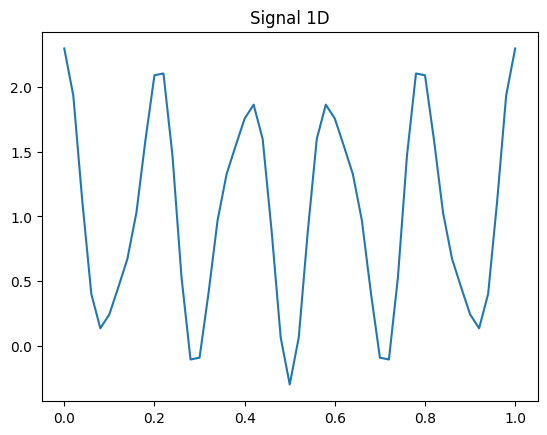

In [64]:
import numpy as np
import matplotlib.pyplot as plt

SR = 50

t = np.arange(0, 1+1/SR, 1/SR) 


s = 1 + np.cos(2 * np.pi * 5 * t) + 0.3 * np.cos(2 * np.pi * 9 * t)


plt.plot(t, s)
plt.title("Signal 1D")
plt.show()

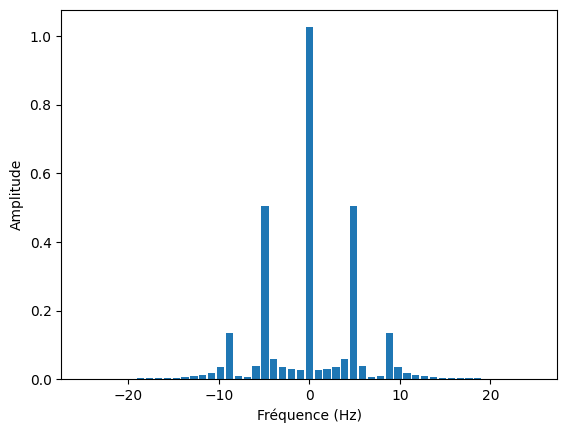

In [66]:
import ressources 
ressources.fourier1D(s, SR)

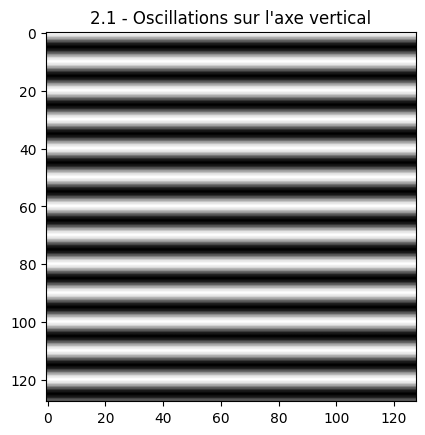

In [87]:
import ressources 
import importlib
importlib.reload(ressources)
img_verticale = ressources.wave(128, 128, 0.1, 0.0)


plt.imshow(img_verticale, cmap='gray')
plt.title("2.1 - Oscillations sur l'axe vertical")
plt.show()

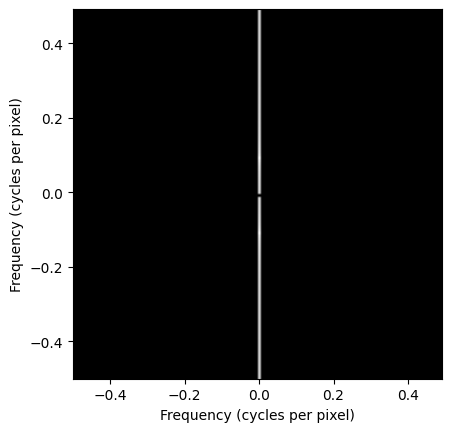

In [89]:
ressources.fourier2d_all(img_verticale)

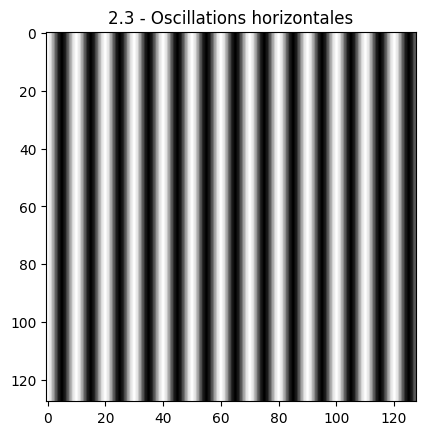

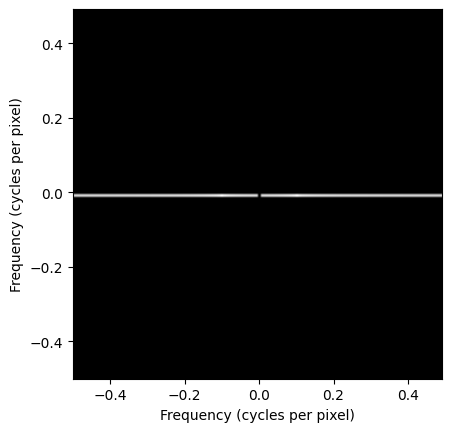

In [91]:

img_horizontale = ressources.wave(128, 128, 0.0, 0.1)


plt.imshow(img_horizontale, cmap='gray')
plt.title("2.3 - Oscillations horizontales")
plt.show()


ressources.fourier2d_all(img_horizontale)

In [93]:
print(dir(ressources))

['__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__spec__', '__warningregistry__', 'fourier1D', 'fourier2d_all', 'fourier2d_many_frequencies', 'fourier2d_single_frenquency', 'fourier2d_vue3d_old', 'np', 'plt', 'wave']


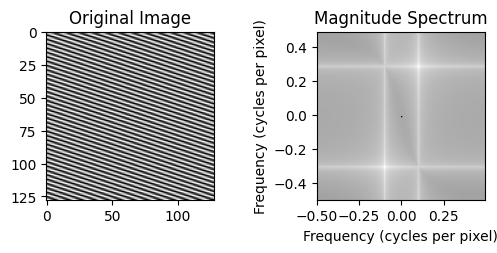

<Figure size 600x500 with 0 Axes>

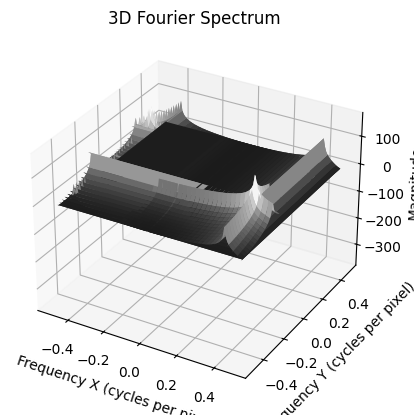

In [96]:
import importlib
import ressources

importlib.reload(ressources)

n, m = 128, 128
fy_mixte = 0.3
fx_mixte = 0.1

img_mixte = ressources.wave(n, m, fy_mixte, fx_mixte)
ressources.fourier2d_all(img_mixte)

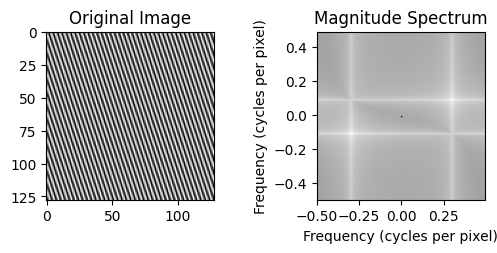

<Figure size 600x500 with 0 Axes>

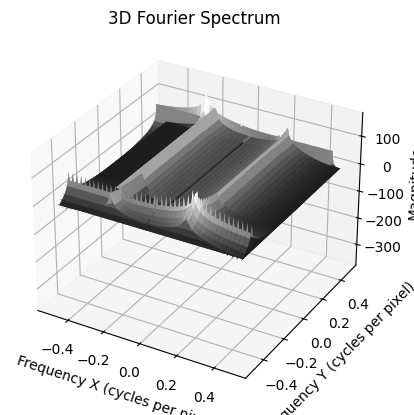

In [100]:
import importlib
import ressources

importlib.reload(ressources)

n, m = 128, 128
fy_mixte = 0.1
fx_mixte = 0.3

img_mixte = ressources.wave(n, m, fy_mixte, fx_mixte)
ressources.fourier2d_all(img_mixte)


--- Analyse de l'image synthétique : eau.bmp ---


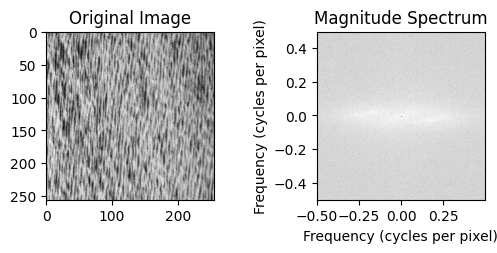

<Figure size 600x500 with 0 Axes>

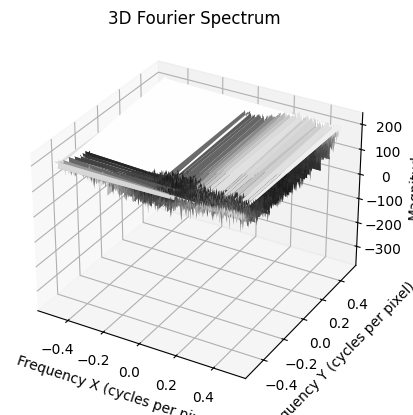


--- Analyse de l'image synthétique : oval0.bmp ---


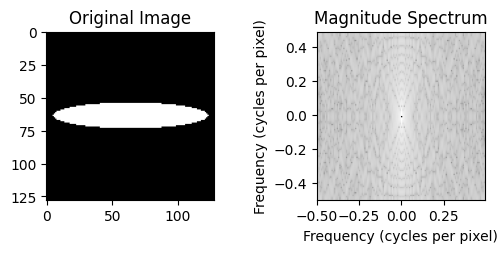

<Figure size 600x500 with 0 Axes>

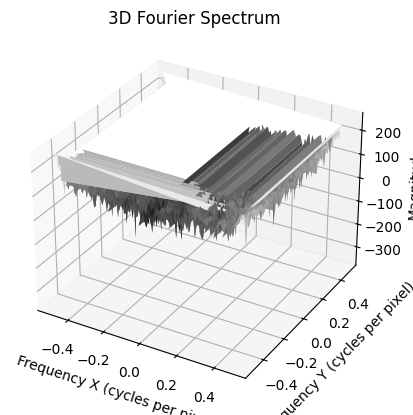


--- Analyse de l'image synthétique : oval2.bmp ---


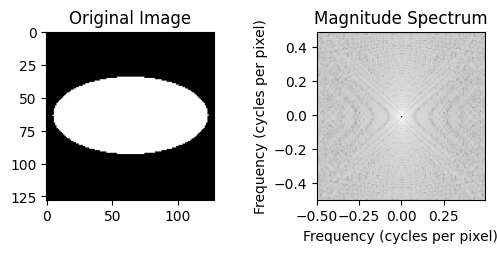

<Figure size 600x500 with 0 Axes>

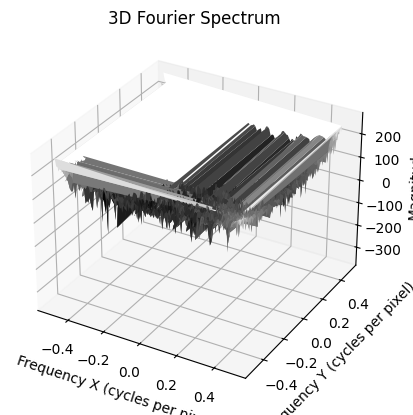


--- Analyse de l'image synthétique : oval3.bmp ---


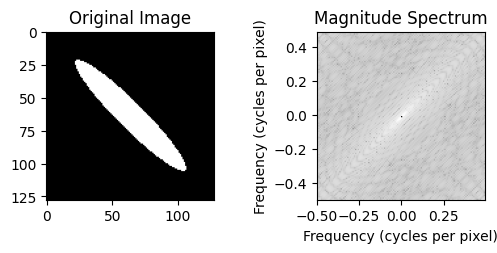

<Figure size 600x500 with 0 Axes>

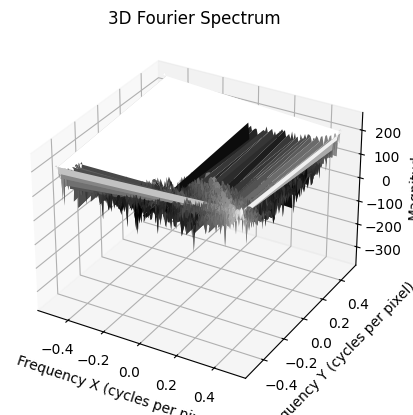


--- Analyse de l'image synthétique : oval5.bmp ---


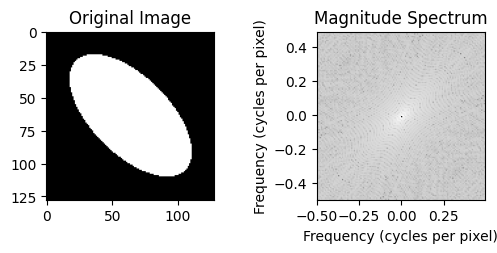

<Figure size 600x500 with 0 Axes>

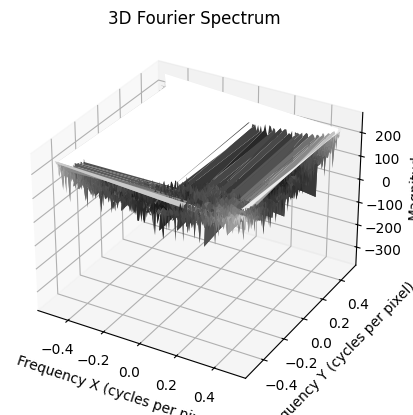


--- Analyse de l'image synthétique : oval6.bmp ---


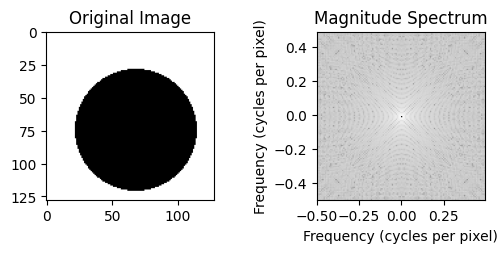

<Figure size 600x500 with 0 Axes>

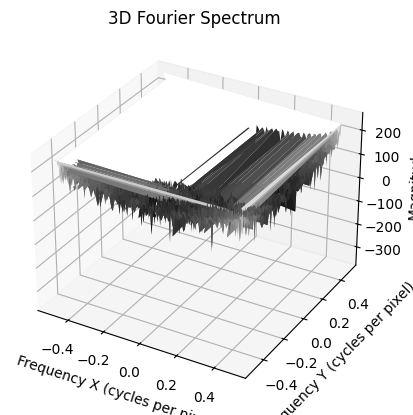


--- Analyse de l'image synthétique : rupt0.bmp ---


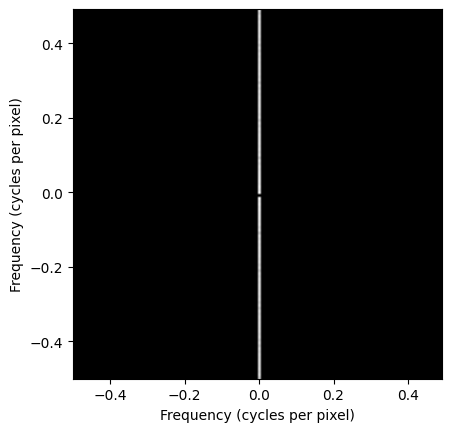


--- Analyse de l'image synthétique : sable.bmp ---


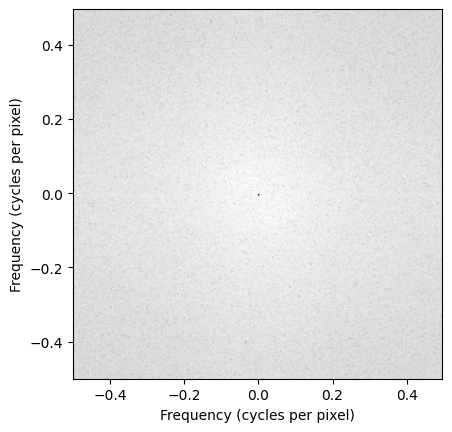

In [108]:
import os
import matplotlib.pyplot as plt
import ressources


dossier = r"C:\Users\pc\Documents\TP2_TI\ressources 2\synthetic_images"


try:
    fichiers = os.listdir(dossier)
    images = [f for f in fichiers if f.lower().endswith(('.bmp', '.jpg', '.jpeg'))]
    
    if not images:
        print("Aucune image trouvée dans le dossier.")
    
    for nom_img in images:
        print(f"\n--- Analyse de l'image synthétique : {nom_img} ---")
        
        
        chemin_complet = os.path.join(dossier, nom_img)
        img = plt.imread(chemin_complet)
        
     
        if len(img.shape) == 3:
            img = img.mean(axis=2)
            
        
        ressources.fourier2d_all(img)

except Exception as e:
    print(f"Une erreur est survenue : {e}")

--- Question 4.1 : Filtrage Passe-Bas ---


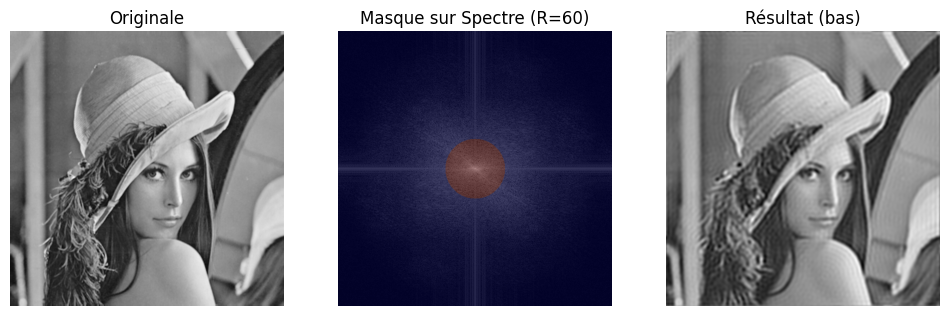

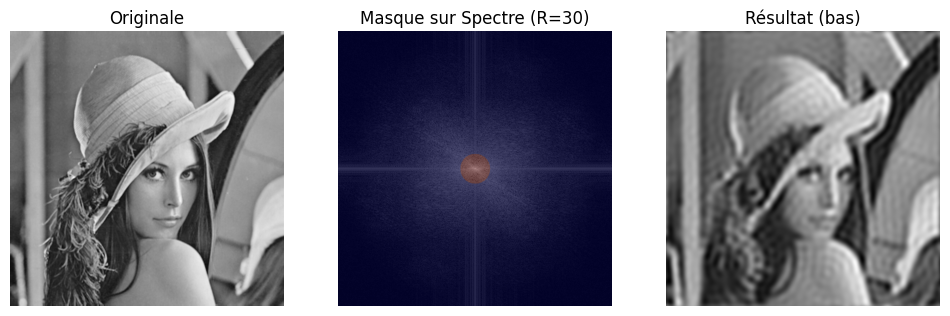

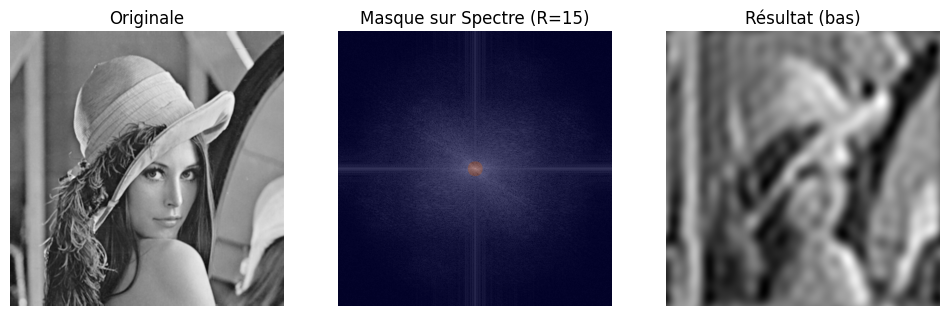

In [112]:
import numpy as np
import matplotlib.pyplot as plt
import os


chemin_lena = r"C:\Users\pc\Documents\TP2_TI\ressources 2\lena.png"

def filtrage_fourier_complet(image_path, rayon, type_filtre='bas'):
   
    if not os.path.exists(image_path):
        print("Erreur : Fichier lena.png non trouvé au chemin spécifié.")
        return
        
    img = plt.imread(image_path)
    if len(img.shape) == 3: 
        img = np.mean(img, axis=2)
    
   
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)
    
    
    lignes, cols = img.shape
    cy, cx = lignes // 2, cols // 2
    Y, X = np.ogrid[:lignes, :cols]
    distance = np.sqrt((X - cx)**2 + (Y - cy)**2)
    
    if type_filtre == 'bas':
        masque = distance <= rayon 
    else:
        masque = distance > rayon  
    
    
    fshift_filtre = fshift * masque
    img_back = np.abs(np.fft.ifft2(np.fft.ifftshift(fshift_filtre)))
    
    # 5. Affichage
    plt.figure(figsize=(12, 4))
    
    plt.subplot(1, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title("Originale")
    plt.axis('off')
    
    plt.subplot(1, 3, 2)

    spectre_log = 20 * np.log(np.abs(fshift) + 1)
    plt.imshow(spectre_log, cmap='gray')
    plt.imshow(masque, alpha=0.3, cmap='jet') 
    plt.title(f"Masque sur Spectre (R={rayon})")
    plt.axis('off')
    
    plt.subplot(1, 3, 3)
    plt.imshow(img_back, cmap='gray')
    plt.title(f"Résultat ({type_filtre})")
    plt.axis('off')
    
    plt.show()


print("--- Question 4.1 : Filtrage Passe-Bas ---")
for r in [60, 30, 15]:
    filtrage_fourier_complet(chemin_lena, r, type_filtre='bas')

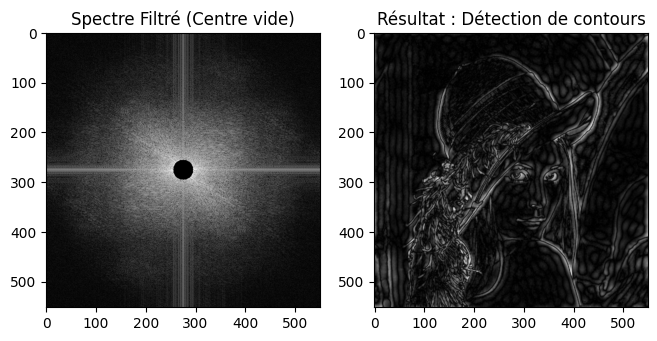

In [116]:
import numpy as np
import matplotlib.pyplot as plt

def filtrage_inverse_passe_haut(image_path, rayon):
   
    img = plt.imread(image_path)
    if len(img.shape) == 3:
        img = np.mean(img, axis=2)

 
    f_shift = np.fft.fftshift(np.fft.fft2(img))

    
    lignes, cols = img.shape
    cy, cx = lignes // 2, cols // 2
    Y, X = np.ogrid[:lignes, :cols]
    distance = np.sqrt((X - cx)**2 + (Y - cy)**2)
    
   
    masque_haut = distance > rayon 

   
    f_shift_filtre = f_shift * masque_haut

    
    img_back = np.fft.ifft2(np.fft.ifftshift(f_shift_filtre))
    img_back = np.abs(img_back)

    # Affichage
    plt.figure(figsize=(12, 5))
    
    
    
    plt.subplot(1, 3, 2)
   
    plt.imshow(np.log(np.abs(f_shift_filtre)+1), cmap='gray')
    plt.title("Spectre Filtré (Centre vide)")
    
    plt.subplot(1, 3, 3)
    plt.imshow(img_back, cmap='gray')
    plt.title("Résultat : Détection de contours")
    
    plt.show()


chemin_lena = r"C:\Users\pc\Documents\TP2_TI\ressources 2\lena.png"
filtrage_inverse_passe_haut(chemin_lena, 20)

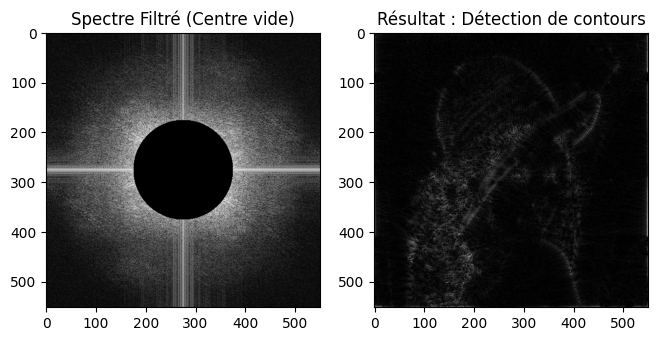

In [118]:
chemin_lena = r"C:\Users\pc\Documents\TP2_TI\ressources 2\lena.png"
filtrage_inverse_passe_haut(chemin_lena, 100)

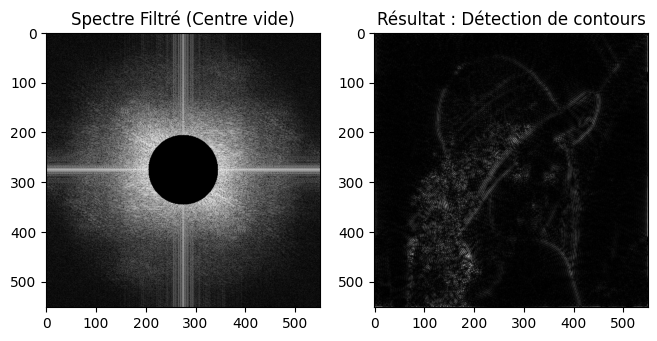

In [120]:
chemin_lena = r"C:\Users\pc\Documents\TP2_TI\ressources 2\lena.png"
filtrage_inverse_passe_haut(chemin_lena, 70)